# Superposition (H) — Qiskit Implementation

**Primitive:** Superposition via Hadamard gate

**SETUP**
- N QUBITS: 2
- GATES APPLIED: Hadamard (H) on every qubit -> equal superposition of all basis states
- QUBIT ORDERING: qubit 0 = rightmost bit in printed bitstring (Qiskit's native convention)
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** The Hadamard gate maps a basis state to an equal-weight superposition:
H|0> = (|0> + |1>)/sqrt(2), H|1> = (|0> - |1>)/sqrt(2). Applying H to every qubit of an
n-qubit register starting in |00...0> produces the uniform superposition
H^(x)n |0...0> = (1/sqrt(2^n)) * sum over all basis states |x>, each with equal probability 1/2^n.
For n=2 this gives all four basis states |00>, |01>, |10>, |11> with probability 0.25 each.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [1]:
# Run this cell first if you get ModuleNotFoundError or MissingOptionalLibraryError.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering -- not pulled in
# automatically by the base qiskit install, so it must be listed explicitly.
!pip install -q qiskit qiskit-aer pylatexenc
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 99.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 94.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.9 MB/s eta 0:00:00


In [2]:
# --- Imports ---
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# --- SETUP constants (all cells below use these -- defined once, here) ---
N_QUBITS = 2
SHOTS = 10000
SEED = 42

## 1. Build the circuit explicitly, gate by gate

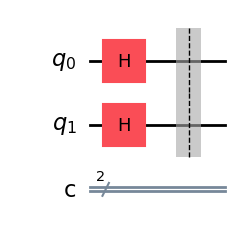

In [3]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="superposition_h")

for q in range(N_QUBITS):
    qc.h(q)  # Superposition operation: Hadamard puts qubit q into (|0>+|1>)/sqrt(2)

qc.barrier()
qc.draw(output="mpl")

## 2. Draw the circuit and save to file

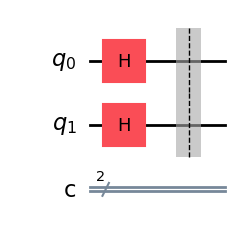

In [4]:
fig = qc.draw(output="mpl")
fig.savefig("superposition_qiskit_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator (Hadamard)

In [5]:
H_matrix = (1 / np.sqrt(2)) * np.array([[1, 1],
                                          [1, -1]], dtype=complex)

print("Single-qubit Hadamard gate matrix:")
print(np.round(H_matrix, 4))

Single-qubit Hadamard gate matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]


In [6]:
prep_circuit = QuantumCircuit(N_QUBITS, name="prep_only")
for q in range(N_QUBITS):
    prep_circuit.h(q)

full_op = Operator(prep_circuit)
print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator H(x)H (basis {{|00>, |01>, |10>, |11>}}):")
print(np.round(full_op.data.real, 4) if np.allclose(full_op.data.imag, 0) else np.round(full_op.data, 4))

Full 4x4 operator H(x)H (basis {|00>, |01>, |10>, |11>}):
[[ 0.5  0.5  0.5  0.5]
 [ 0.5 -0.5  0.5 -0.5]
 [ 0.5  0.5 -0.5 -0.5]
 [ 0.5 -0.5 -0.5  0.5]]


## 4. Exact statevector (before measurement), global-phase normalized

In [7]:
sv = Statevector.from_instruction(qc)
amps = sv.data.copy()

def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.25), '01': np.float64(0.25), '10': np.float64(0.25), '11': np.float64(0.25)}


**Ordering note:** Qiskit's `Statevector` already indexes amplitudes with qubit 0 as the
least-significant (rightmost) bit of the binary index -- matches the SETUP convention
directly, so no reversal was needed here.

## 5. Measurement: add measurements, run AerSimulator, plot histogram

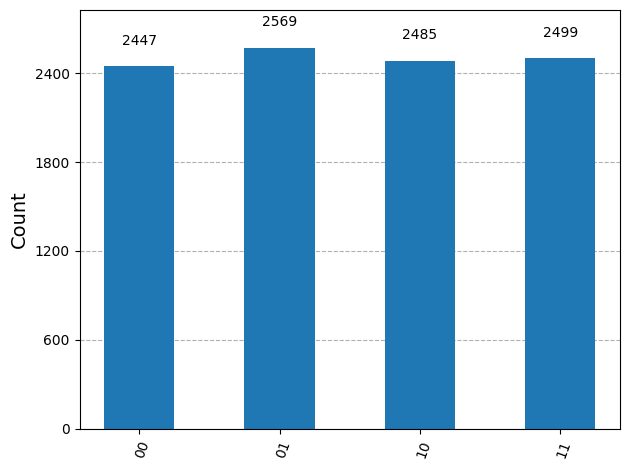

In [8]:
qc_measured = qc.copy()
qc_measured.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_measured, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

fig2 = plot_histogram(counts)
fig2.savefig("superposition_qiskit_histogram.png", bbox_inches="tight")
fig2

In [9]:
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}):")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42):
{'00': 0.2447, '01': 0.2569, '10': 0.2485, '11': 0.2499}


## 6. Circuit resource counts

In [10]:
print(f"Depth: {qc_measured.depth()}")
print(f"Gate/operation count: {qc_measured.size()}")

Depth: 2
Gate/operation count: 4


## 7. Convention notes

In [11]:
print("Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the")
print("rightmost (least-significant) bit of the printed bitstring, matching this notebook's")
print("SETUP convention exactly -> NO reversal applied.")
print()
print("Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring")
print("order and rotating the whole statevector so that amplitude becomes real and positive.")
print("For this all-H circuit every amplitude is already real and positive (1/2), so the")
print("normalization step is a no-op here -- included anyway to keep the pipeline identical")
print("across every primitive in this study.")

Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the
rightmost (least-significant) bit of the printed bitstring, matching this notebook's
SETUP convention exactly -> NO reversal applied.

Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring
order and rotating the whole statevector so that amplitude becomes real and positive.
For this all-H circuit every amplitude is already real and positive (1/2), so the
normalization step is a no-op here -- included anyway to keep the pipeline identical
across every primitive in this study.


## Final result (for diffing against the CUDA-Q version)

In [12]:
QISKIT_RESULT = exact_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'00': np.float64(0.25), '01': np.float64(0.25), '10': np.float64(0.25), '11': np.float64(0.25)}
